In [82]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm

In [2]:
logdir = "runs"
reader = SummaryReader(logdir, extra_columns={"dir_name"}, event_types={'scalars'})

In [83]:
data = reader.scalars
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.sort_values("step")

In [90]:
IMPORTANT_STATS = [
    "reward/mean",
    "observation/progress_metres",
    "collision/per_episode",
    "collision/per_step",
    "observation/forward_velocity"
]
data["tag"].unique()

array(['aux/r2_score_angular_velocity_y',
       'aux/r2_score_track_curvature_0_50',
       'aux/r2_score_wheel_slip_lateral_front_right',
       'loss/aux_track_curvature_4_00', 'loss/entropy',
       'loss/aux_track_curvature_3_50',
       'aux/r2_score_track_curvature_3_00', 'reward/forward_velocity',
       'loss/aux_track_curvature_6_50',
       'loss/aux_wheel_slip_lateral_back_left',
       'loss/aux_track_curvature_2_00', 'loss/aux_angular_velocity_y',
       'loss/aux_track_curvature_3_00',
       'grad/cos_aux_policy_track_curvature_2_00',
       'grad/norm_aux_track_curvature_5_00',
       'loss/aux_track_curvature_2_50', 'loss/max_ratio', 'loss/ESS',
       'collision/per_episode', 'loss/kl_approx', 'loss/loss_objective',
       'loss/aux_wheel_slip_lateral_back_right', 'loss/loss_entropy',
       'time/save_rollout_buffer',
       'loss/aux_wheel_slip_forward_front_left',
       'aux/r2_score_track_curvature_1_50', 'loss/explained_variance',
       'grad/cos_aux_policy_wh

In [33]:
RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]

,run_category,run_seed,aux_weight,tag,mean,std
0,all,s0,0.1,aux/r2_score_angular_velocity_y,0.949837,0.004873
1,all,s0,0.1,aux/r2_score_track_curvature_0_50,0.658350,0.011870
2,all,s0,0.1,aux/r2_score_track_curvature_1_00,0.701445,0.014705
3,all,s0,0.1,aux/r2_score_track_curvature_1_50,0.583510,0.012693
4,all,s0,0.1,aux/r2_score_track_curvature_2_00,0.508017,0.011282
...,...,...,...,...,...,...
9444,wheel_slip_rear_lateral,s2,1,time/gae,1.112361,0.178278
9445,wheel_slip_rear_lateral,s2,1,time/rollout,13.335293,1.273278
9446,wheel_slip_rear_lateral,s2,1,time/save_rollout_buffer,0.054895,0.012531
9447,wheel_slip_rear_lateral,s2,1,time/stack_rollout,0.267181,0.055012


In [5]:
def auc(g):
    return np.trapezoid(g["value"], g["step"])


completed_runs = data[data["step"] == 599]

rewards = data[(data["tag"] == "reward/mean")].sort_values("step")
# get only the ones that are finished
rewards = rewards[rewards.groupby("run_name")["step"].transform("max") >= 599]

auc_df = (
    rewards.groupby(["run_category", "aux_weight", "run_seed"])
           .apply(auc, include_groups=False)
           .rename("auc")
           .reset_index()
)
last_n = 50

last_steps_mean_reward = (
    rewards[rewards["step"] > 599 - last_n]          # steps 550-599 (50 steps)
    .groupby(["run_category", "aux_weight", "run_seed"])["value"]
    .mean()
    .rename("last_50_mean_reward")
    .reset_index()
)
last_steps_mean_reward

,run_category,aux_weight,run_seed,last_50_mean_reward
0,all,0.1,s0,0.175062
1,all,0.1,s1,0.161085
2,all,0.1,s2,0.168969
3,all,0.3,s0,0.162019
4,all,0.3,s1,0.171508
...,...,...,...,...
101,wheel_slip_rear_lateral,0.3,s1,0.174625
102,wheel_slip_rear_lateral,0.3,s2,0.098033
103,wheel_slip_rear_lateral,1,s0,0.158871
104,wheel_slip_rear_lateral,1,s1,0.057452


<Axes: xlabel='step', ylabel='value'>

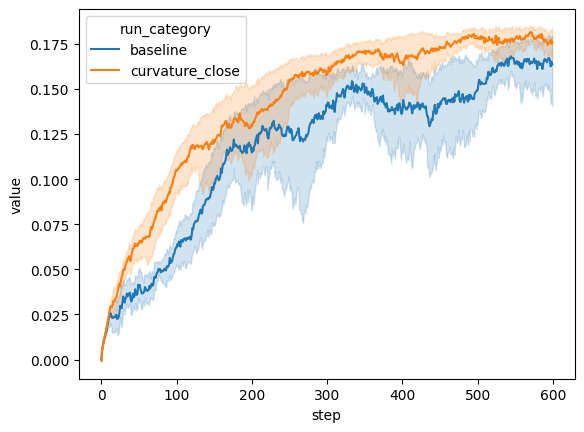

In [7]:
sns.lineplot(data[data["run_category"].isin(["baseline", "curvature_close"]) & (data["tag"] == "reward/mean")], x="step", y="value", hue="run_category")

In [ ]:
data[data["tag"] == "reward/mean"].groupby(RUN_COLUMNS)

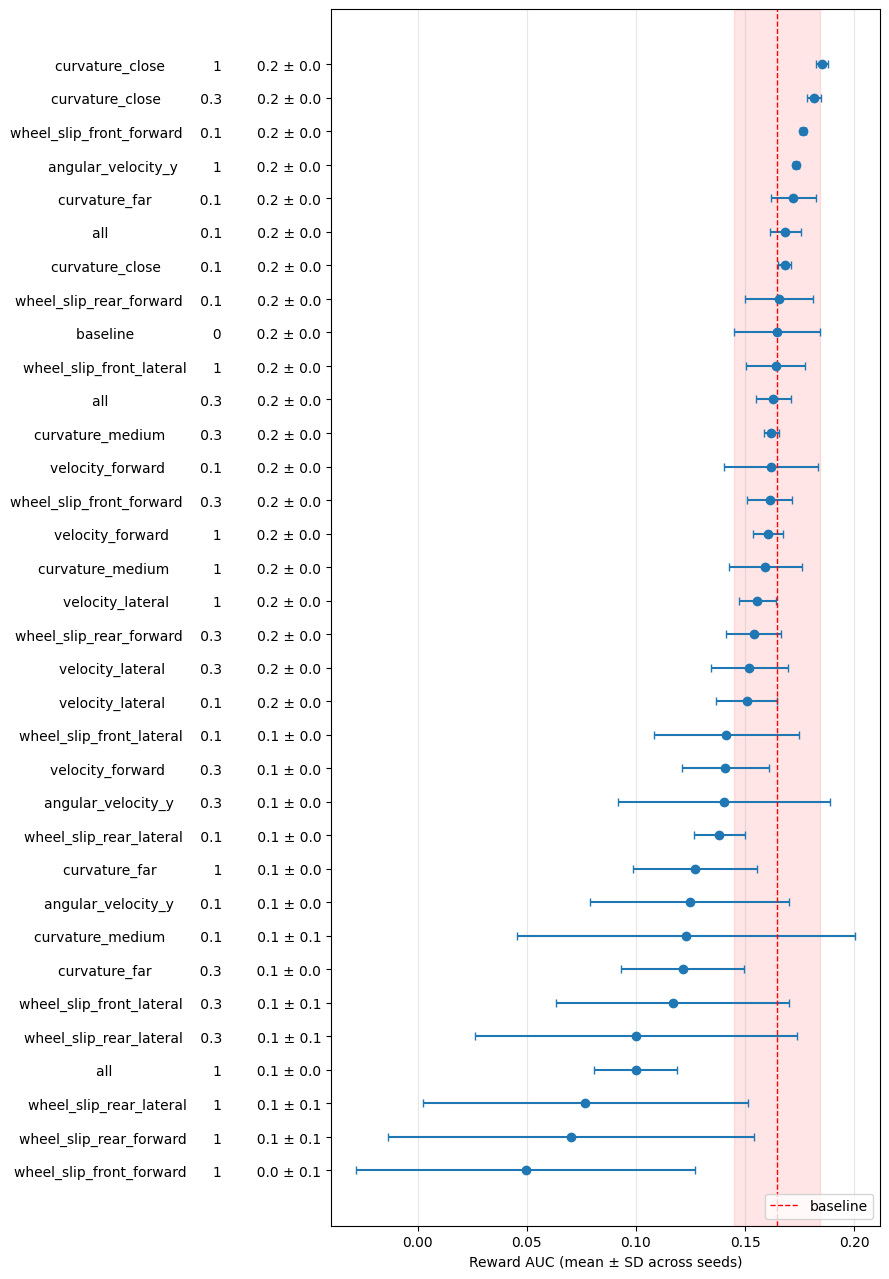

In [ ]:
summary = (
    last_steps_mean_reward.groupby(["run_category", "aux_weight"])["last_50_mean_reward"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
    .sort_values("mean")
    .reset_index(drop=True)
)

labels = [
    f"{r.run_category:<20} {r.aux_weight:>6}   {r['mean']:8.1f} ± {r['std']:.1f}"
    for _, r in summary.iterrows()
]

fig, ax = plt.subplots(figsize=(9, 0.35 * len(summary) + 1))
ax.errorbar(summary["mean"], summary.index,
            xerr=summary["std"], fmt="o", capsize=3)

ax.set_yticks(summary.index, labels)
ax.set_xlabel("Reward AUC (mean ± SD across seeds)")
ax.grid(axis="x", alpha=0.3)

base = summary[summary["run_category"] == "baseline"].iloc[0]

ax.axvline(base["mean"], color="red", ls="--", lw=1, label="baseline")
ax.axvspan(base["mean"] - base["std"], base["mean"] +
           base["std"], color="red", alpha=0.1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/primary_task_auc_dumbbells.pdf")

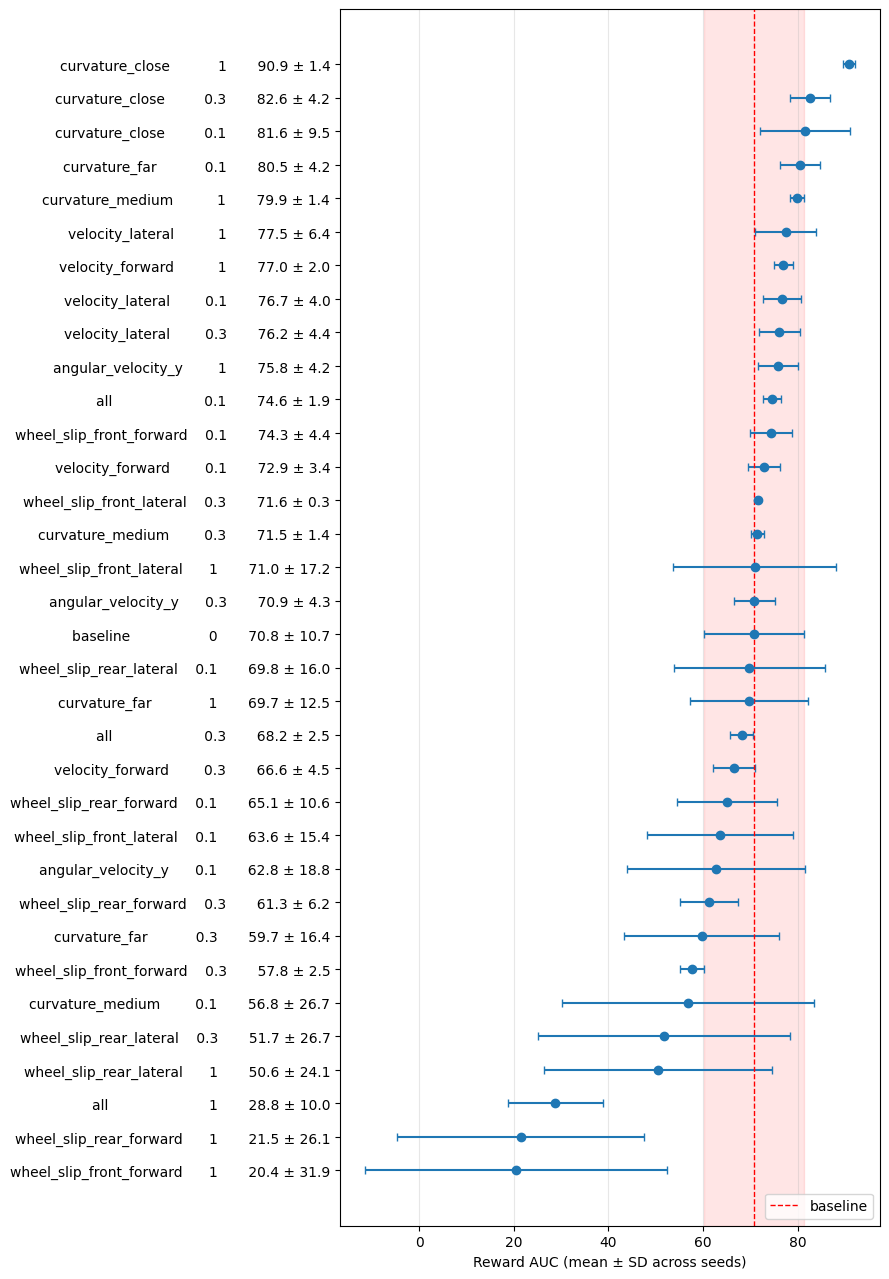

In [11]:
summary = (
    auc_df.groupby(["run_category", "aux_weight"])["auc"]
          .agg(["mean", "std"])
          .reset_index()
          .sort_values("mean")
          .reset_index(drop=True)
)

labels = [
    f"{r.run_category:<20} {r.aux_weight:>6}   {r['mean']:8.1f} ± {r['std']:.1f}"
    for _, r in summary.iterrows()
]

fig, ax = plt.subplots(figsize=(9, 0.35 * len(summary) + 1))
ax.errorbar(summary["mean"], summary.index, xerr=summary["std"], fmt="o", capsize=3)

ax.set_yticks(summary.index, labels)
ax.set_xlabel("Reward AUC (mean ± SD across seeds)")
ax.grid(axis="x", alpha=0.3)

base = summary[summary["run_category"] == "baseline"].iloc[0]

ax.axvline(base["mean"], color="red", ls="--", lw=1, label="baseline")
ax.axvspan(base["mean"] - base["std"], base["mean"] + base["std"], color="red", alpha=0.1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/primary_task_auc_dumbbells.pdf")

In [15]:
auc_df.groupby(["run_category", "aux_weight"])["auc"] \
          .agg(["mean", "std"])\
        .reset_index()

,run_category,aux_weight,mean,std
0,all,0.1,74.619551,1.868166
1,all,0.3,68.176718,2.480832
2,all,1,28.755052,10.009139
3,angular_velocity_y,0.1,62.763621,18.762706
4,angular_velocity_y,0.3,70.893623,4.251219
5,angular_velocity_y,1,75.805012,4.205641
6,baseline,0,70.767120,10.651500
7,curvature_close,0.1,81.569572,9.476922
8,curvature_close,0.3,82.577189,4.194050
9,curvature_close,1,90.885556,1.356020


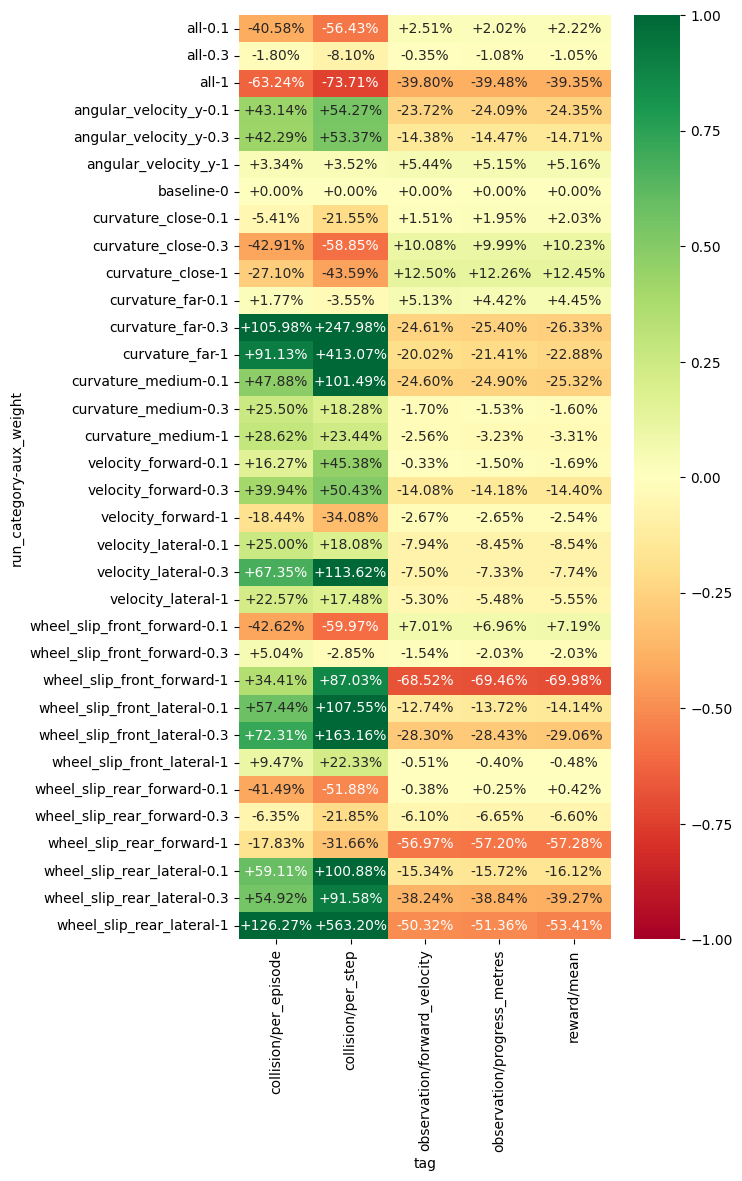

In [92]:
last_50_steps = data[data["step"] > 599 - 50]\
    .groupby(RUN_COLUMNS + ["tag"])["value"] \
    .agg(["mean", "std"]) \
    .reset_index()

stats = last_50_steps[last_50_steps["tag"].isin(IMPORTANT_STATS)]

pivot = stats.pivot_table(
    index="tag",
    columns=["run_category", "aux_weight"],
    values="mean",
)

# Baseline per tag. Adjust if baseline has multiple aux_weight values.
baseline = pivot["baseline"].mean(axis=1)   # Series indexed by tag

# Subtract baseline from every column, aligning on the tag index
diff = pivot.div(baseline, axis=0)

diff -= 1

plt.figure(figsize=(6, 12))
sns.heatmap(
    diff.T,
    center=0.0,
    vmax=1.0,
    cmap="RdYlGn",
    annot=True,
    fmt="+.2%",
    vmin=-1.0
)
plt.show()

In [95]:
data[(data["tag"] == "observation/forward_velocity") & (data["step"] > 599 - 50) & (data["run_category"] == "baseline")]["value"].mean()

np.float64(3.848117093358721)